Clase FRA: 18 partículas de referencia
Clase PEL: 12 partículas de referencia
Clase TAR: 8 partículas de referencia

========== RESULTADOS ==========
Partículas evaluadas: 120
Accuracy: 0.700
Precision: 0.702
Recall: 0.700
F1-score: 0.687


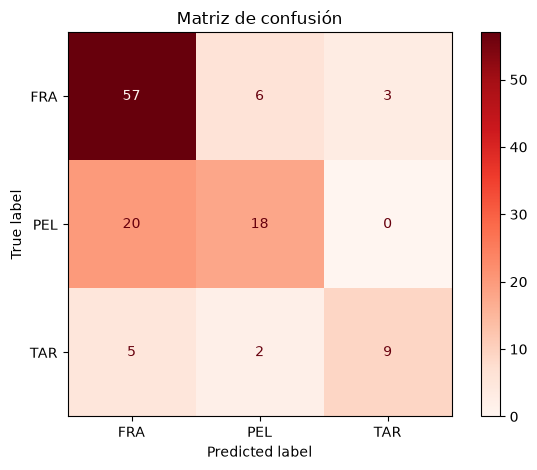

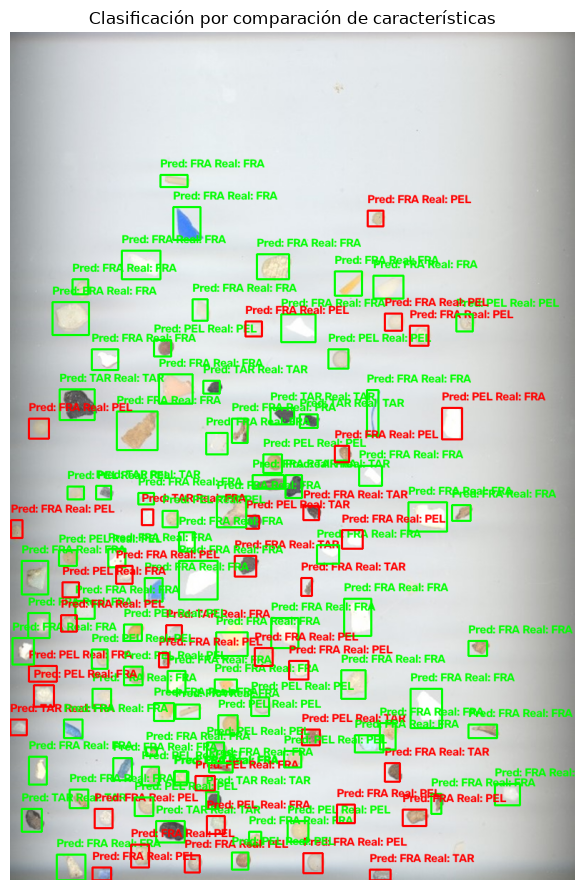

In [ ]:
import csv
import cv2
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Imagenes para obtener las características
TRAIN_IMAGES = {
    "FRA": "FRA.png",
    "PEL": "PEL.png",
    "TAR": "TAR.png",
}

# Imagen con todo junto mezclado para probar
TEST_IMAGE_PATH = "test.jpg"
CSV_PATH = "MPs_test_bbs.csv"

MIN_AREA = 10 # Se utilizan los contornos mayores a 10 píxeles cuadrados
K_NEIGHBORS = 3 # K = numero de referencias para comparar cada partícula con las tres referencias más cercanas de cada clase.

# Pesos para las características:
# Compacity, solidity, aspect_ratio, ellipse_ratio, area_box
FEATURE_WEIGHTS = np.array([1.5, 1.5, 1.5, 1.0, 20.0])
# Distancia geométrica
SHAPE_WEIGHT = 0.8 
# Color
COLOR_WEIGHT = 0.2


def load_image(path):
    image = cv2.imread(path)

    if image is None:
        raise FileNotFoundError(f"No se encuentra la imagen: {path}")

    return image


def extract_particles(image, gray=None):
    if image is None:
        return []

    if gray is None:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    _, mask = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU,
    )

    border = np.concatenate((
        mask[0, :],
        mask[-1, :],
        mask[:, 0],
        mask[:, -1],
    ))

    # Se determina el color del fondo:
    if np.mean(border) > 127:
        mask = cv2.bitwise_not(mask)

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )

    # Se devuelven todos los contornos mayores a la area mínima
    return [
        contour
        for contour in contours
        if cv2.contourArea(contour) >= MIN_AREA
    ]


def extract_features(image, contour, gray=None, hsv=None):
    if image is None or contour is None or len(contour) == 0:
        return None

    if gray is None:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    if hsv is None:
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    if area <= 0 or perimeter <= 0:
        return None

    x, y, width, height = cv2.boundingRect(contour)

    if width <= 0 or height <= 0:
        return None

    circularity = 4 * np.pi * area / (perimeter ** 2)
    solidity_area = area / (width * height)
    aspect_ratio = min(width, height) / max(width, height)

    ellipse_ratio = 0.0

    if len(contour) >= 5:
        _, axes, _ = cv2.fitEllipse(contour)
        axis_min, axis_max = min(axes), max(axes)

        if axis_max > 0:
            ellipse_ratio = axis_min / axis_max

    mask = np.zeros(gray.shape, dtype=np.uint8)
    cv2.drawContours(
        mask,
        [contour],
        -1,
        255,
        thickness=cv2.FILLED,
    )

    pixels = image[mask > 0]

    if pixels.size == 0:
        return None

    mean_hsv = cv2.mean(hsv, mask=mask)[:3]

    hull = cv2.convexHull(contour)
    hull_area = cv2.contourArea(hull)

    solidity = area / hull_area if hull_area > 0 else 0.0

    return np.array(
        [
            circularity,
            solidity,
            aspect_ratio,
            ellipse_ratio,
            solidity_area,
            *mean_hsv,
        ],
        dtype=float,
    )

# Mediante esta funcion se calculan las características de cada imagen de referencia FRA, PEL y TAR y las guardamos para poder compararlas mas adelante
def build_reference_features(train_images):
    reference_features = {}

    for label, path in train_images.items():
        image = load_image(path)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        contours = extract_particles(image, gray)
        features_list = [
            features
            for contour in contours
            if (
                features := extract_features(
                    image,
                    contour,
                    gray,
                    hsv,
                )
            ) is not None
        ]

        if not features_list:
            raise ValueError(
                f"No se detectaron partículas en {path}. "
                "Revisa la segmentación y MIN_AREA."
            )

        reference_features[label] = np.array(
            features_list,
            dtype=float,
        )

        print(
            f"Clase {label}: "
            f"{len(features_list)} partículas de referencia"
        )

    return reference_features

# Normalizamos las referencias
def fit_normalizer(reference_features):
    all_features = np.vstack(list(reference_features.values()))

    # Se calcula la mediana de cada caracteristica
    center = np.median(all_features, axis=0)

    # Se calcula el rango intercuartílico
    # Este rango mide la dispersión de los valores centrales de cada característica
    q75, q25 = np.percentile(
        all_features,
        [75, 25],
        axis=0,
    )
    scale = q75 - q25
    fallback = np.std(all_features, axis=0)
    scale = np.where(scale > 1e-8, scale, fallback)
    scale = np.where(scale > 1e-8, scale, 1.0)

    # Normalizamos las características z = (x-mediana)/escala
    normalized_features = {
        label: (features - center) / scale
        for label, features in reference_features.items()
    }

    return center, scale, normalized_features


def classify_particle(
    crop,
    feature_center,
    feature_scale,
    normalized_references,
):
    # Se detecta la partícula dentro de cada recorte (crop)
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    contours = extract_particles(crop, gray)

    if not contours:
        return None, {}

    # En caso de encontrarse varios contornos, seleccionamos el mayor:
    contour = max(contours, key=cv2.contourArea)

    # Se extraen y se normalizan las características de el contorno
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    features = extract_features(crop, contour, gray, hsv)
    if features is None:
        return None, {}
    # Normalización:
    vector = (features - feature_center) / feature_scale
    
    # Calculamos la distancia geometrica para las 5 características geometricas
    # cada característica tiene un peso asignado:
    # Característica:
    # Circularidad	            1.5
    # Solidez	                1.5
    # Relación de aspecto	    1.5
    # Relación de ejes	        1.0
    # Ocupación del rectángulo	20.0

    class_distances = {}
    for label, reference_vectors in normalized_references.items():
        differences = reference_vectors - vector

        shape_distances = np.sqrt(
            np.sum(
                differences[:, :5] ** 2 * FEATURE_WEIGHTS,
                axis=1,
            )
        )

        # Se calcula tambien la distancia del color por separado HSV
        color_distances = np.linalg.norm(
            differences[:, 5:8],
            axis=1,
        )

        # Distancia final:
        distances = (
            SHAPE_WEIGHT * shape_distances
            + COLOR_WEIGHT * color_distances
        )

        # Se seleccionan las 3 referencias mas cercanas
        k = min(K_NEIGHBORS, len(distances))
        nearest = np.partition(distances, k - 1)[:k]
        class_distances[label] = float(np.mean(nearest))

    prediction = min(class_distances, key=class_distances.get)

    return prediction, class_distances


def evaluate_predictions(y_true, y_pred):
    if not y_true:
        print(
            "No se han podido evaluar partículas. "
            "Revisa el CSV y la segmentación."
        )
        return

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1-score": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        ),
    }

    print("\n========== RESULTADOS ==========")
    print(f"Partículas evaluadas: {len(y_true)}")

    for name, value in metrics.items():
        print(f"{name}: {value:.3f}")

    classes = sorted(set(y_true) | set(y_pred))

    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=classes,
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=classes,
    )

    display.plot(cmap="Reds", values_format="d")
    plt.title("Matriz de confusión")
    plt.tight_layout()
    plt.show()

# Esta funcion se encarga de conectar el clasificador con los datos obtenidos de la imagen del test
def classify_test_image(
    image_path,
    csv_path,
    feature_center,
    feature_scale,
    normalized_references,
):
    test_image = load_image(image_path)
    height, width = test_image.shape[:2]

    result_image = cv2.cvtColor(
        test_image,
        cv2.COLOR_BGR2RGB,
    )

    y_true = []
    y_pred = []

    # Leemos el csv y obtenemos los datos
    with open(csv_path, newline="", encoding="utf-8-sig") as file:
        reader = csv.DictReader(file)

        for row in reader:
            label_true = row["label"].strip().upper()

            x1 = max(0, min(int(float(row["x_min"])), width))
            y1 = max(0, min(int(float(row["y_min"])), height))
            x2 = max(0, min(int(float(row["x_max"])), width))
            y2 = max(0, min(int(float(row["y_max"])), height))

            if x2 <= x1 or y2 <= y1:
                print("Bounding box no válido:", row)
                continue
            
            # Se recorta y se clasifica
            crop = test_image[y1:y2, x1:x2]

            label_pred, _ = classify_particle(
                crop,
                feature_center,
                feature_scale,
                normalized_references,
            )

            if label_pred is None:
                print("No se pudieron extraer características:", row)
                continue

            # Añadimos los valores de prediccion y reales a las dos listas
            y_true.append(label_true)
            y_pred.append(label_pred)

            # Asignamos un color verde en el caso de que la prediccion sea igual que el real y un color rojo en el caso de que no
            color = (
                (0, 255, 0)
                if label_pred == label_true
                else (255, 0, 0)
            )

            # Dibujamos el rectangulo de ese color
            cv2.rectangle(
                result_image,
                (x1, y1),
                (x2, y2),
                color,
                2,
            )

            cv2.putText(
                result_image,
                f"Pred: {label_pred} Real: {label_true}",
                (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                color,
                2,
            )

    return y_true, y_pred, result_image


def main():

    # Orden de ejecución:

    # 1. build_reference_features(TRAIN_IMAGES): extrae las características de las imágenes de referencia FRA, PEL y TAR.
    # 2. fit_normalizer(reference_features): calcula los valores necesarios para normalizar las características y normaliza las referencias.
    # 3. classify_test_image(...): analiza la imagen de prueba, extrae sus partículas y las clasifica comparándolas con las referencias normalizadas.
    # 4. evaluate_predictions(y_true, y_pred): evalúa los resultados de la clasificación mediante métricas y la matriz de confusión.
    # 5. plt.figure(...): crea la figura donde se mostrará la imagen resultante.
    # 6. plt.imshow(result_image): muestra la imagen con las partículas clasificadas.
    # 7. plt.title(...): añade el título a la figura.
    # 8. plt.axis("off"): oculta los ejes.
    # 9. plt.tight_layout(): ajusta la distribución de la figura.
    # 10. plt.show(): muestra la figura en pantalla.  

    reference_features = build_reference_features(TRAIN_IMAGES)

    feature_center, feature_scale, normalized_references = (
        fit_normalizer(reference_features)
    )

    y_true, y_pred, result_image = classify_test_image(
        TEST_IMAGE_PATH,
        CSV_PATH,
        feature_center,
        feature_scale,
        normalized_references,
    )

    evaluate_predictions(y_true, y_pred)

    plt.figure(figsize=(14, 9))
    plt.imshow(result_image)
    plt.title("Clasificación por comparación de características")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()
